# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize,
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

In [3]:
import matplotlib.pyplot as plt
import numpy as np

def plot_n_queens(board):
    n = len(board)
    board = np.array(board)
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(np.indices((n, n)).sum(axis=0) % 2, cmap='Accent', alpha=0.3)

    for col, row in enumerate(board):
        ax.text(col, row, '♕', fontsize=28, ha='center', va='center', color='purple', weight='bold')

    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.grid(color='black', linestyle='-', linewidth=1)
    plt.show()

## Create a board

Board with 9 conflicts.


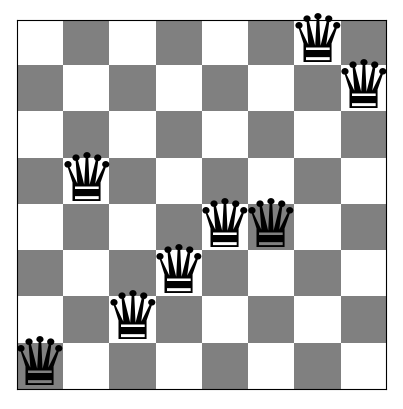

Queens (left to right) are at rows: [7 3 6 5 4 4 0 1]
Number of conflicts: 9


In [4]:
board = random_board(8)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


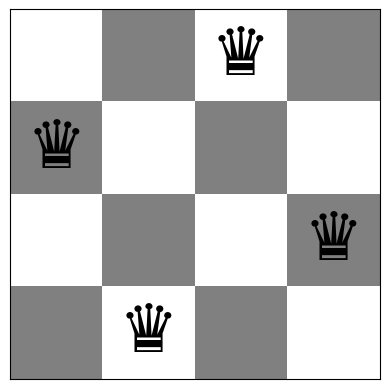

In [5]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum.

--- STEEPEST-ASCENT HILL CLIMBING ---
Bàn cờ ban đầu: [7 1 7 1 2 6 3 6]
Bàn cờ kết quả: [4 1 7 5 2 0 3 6]
Số xung đột cuối cùng (f): 1
Số bước lặp: 4 | Số lần gọi conflicts(): 225 | Thời gian: 1.54 ms


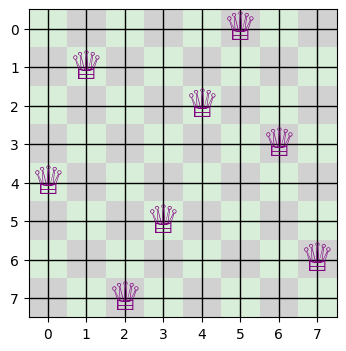

In [6]:
# Code and description go here
import time
import numpy as np
import random

def steepest_ascent_n_queens(initial_board, max_steps=1000):
    current = np.array(initial_board)
    n = len(current)
    steps = 0
    eval_count = 0
    start_time = time.time()

    current_score = conflicts(current)
    eval_count += 1

    for _ in range(max_steps):
        steps += 1
        min_neighbor_score = current_score
        best_candidates = []

        # Duyệt tất cả các láng giềng (thay đổi hàng của từng quân hậu trong từng cột)
        for col in range(n):
            original_row = current[col]
            for row in range(n):
                if row == original_row:
                    continue
                neighbor = np.copy(current)
                neighbor[col] = row
                score = conflicts(neighbor)
                eval_count += 1

                # Tìm láng giềng có số xung đột nhỏ nhất
                if score < min_neighbor_score:
                    min_neighbor_score = score
                    best_candidates = [neighbor]
                elif score == min_neighbor_score and min_neighbor_score < current_score:
                    best_candidates.append(neighbor)

        # Nếu không có láng giềng nào tốt hơn -> Dừng (kẹt ở cực trị cục bộ hoặc đã đạt tối ưu)
        if min_neighbor_score >= current_score:
            break

        # Chọn ngẫu nhiên một trong các láng giềng tốt nhất
        current = random.choice(best_candidates)
        current_score = min_neighbor_score

        if current_score == 0:
            break

    end_time = time.time()
    runtime = (end_time - start_time) * 1000 # tính bằng ms
    return current, current_score, steps, eval_count, runtime

# Chạy thử nghiệm Task 1
board_init = random_board(8)
final_board, final_f, steps, evals, runtime = steepest_ascent_n_queens(board_init)
print("--- STEEPEST-ASCENT HILL CLIMBING ---")
print(f"Bàn cờ ban đầu: {board_init}")
print(f"Bàn cờ kết quả: {final_board}")
print(f"Số xung đột cuối cùng (f): {final_f}")
print(f"Số bước lặp: {steps} | Số lần gọi conflicts(): {evals} | Thời gian: {runtime:.2f} ms")
plot_n_queens(final_board)

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.


--- INEFFICIENT STOCHASTIC HILL CLIMBING ---
Số xung đột cuối cùng (f): 2
Số bước lặp: 4 | Số lần gọi conflicts(): 228 | Thời gian: 1.48 ms


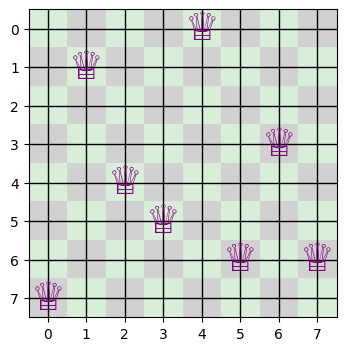

In [7]:
# Code and description go here
def inefficient_stochastic_n_queens(initial_board, max_steps=1000):
    current = np.array(initial_board)
    n = len(current)
    steps = 0
    eval_count = 0
    start_time = time.time()

    current_score = conflicts(current)
    eval_count += 1

    for _ in range(max_steps):
        steps += 1
        improving_neighbors = []

        # Duyệt toàn bộ láng giềng, thu thập các láng giềng có điểm số tốt hơn hiện tại
        for col in range(n):
            original_row = current[col]
            for row in range(n):
                if row == original_row:
                    continue
                neighbor = np.copy(current)
                neighbor[col] = row
                score = conflicts(neighbor)
                eval_count += 1

                if score < current_score:
                    improving_neighbors.append(neighbor)

        # Nếu không tìm thấy láng giềng nào cải thiện -> Dừng
        if not improving_neighbors:
            break

        # Chọn ngẫu nhiên một láng giềng trong danh sách cải thiện
        current = random.choice(improving_neighbors)
        current_score = conflicts(current)
        eval_count += 1

        if current_score == 0:
            break

    end_time = time.time()
    runtime = (end_time - start_time) * 1000
    return current, current_score, steps, eval_count, runtime

# Chạy thử nghiệm Task 2
final_board, final_f, steps, evals, runtime = inefficient_stochastic_n_queens(board_init)
print("\n--- INEFFICIENT STOCHASTIC HILL CLIMBING ---")
print(f"Số xung đột cuối cùng (f): {final_f}")
print(f"Số bước lặp: {steps} | Số lần gọi conflicts(): {evals} | Thời gian: {runtime:.2f} ms")
plot_n_queens(final_board)

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.


--- EFFICIENT STOCHASTIC HILL CLIMBING ---
Số xung đột cuối cùng (f): 3
Số bước lặp: 3 | Số lần gọi hàm conflicts(): 143 | Thời gian: 1.11 ms


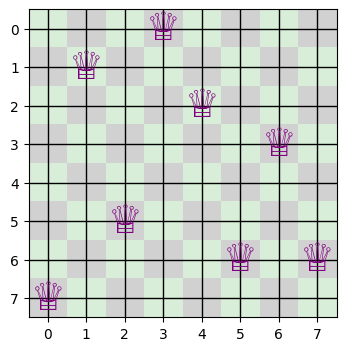

In [8]:
# Code and description go here
def efficient_stochastic_n_queens(initial_board, max_trials=100, max_steps=1000):
    current = np.array(initial_board)
    n = len(current)
    steps = 0
    eval_count = 0
    start_time = time.time()

    current_score = conflicts(current)
    eval_count += 1

    for _ in range(max_steps):
        steps += 1
        improved = False

        # Thử ngẫu nhiên tối đa max_trials lần để tìm láng giềng tốt hơn
        for _ in range(max_trials):
            col = random.randint(0, n - 1)
            row = random.randint(0, n - 1)
            while row == current[col]:
                row = random.randint(0, n - 1)

            neighbor = np.copy(current)
            neighbor[col] = row
            score = conflicts(neighbor)
            eval_count += 1

            # Chấp nhận ngay nếu tìm thấy láng giềng cải thiện
            if score < current_score:
                current = neighbor
                current_score = score
                improved = True
                break

        # Nếu hết số lần thử mà không tìm được láng giềng tốt hơn -> Dừng
        if not improved:
            break

        if current_score == 0:
            break

    end_time = time.time()
    runtime = (end_time - start_time) * 1000
    return current, current_score, steps, eval_count, runtime

# Chạy thử nghiệm Task 3
final_board, final_f, steps, evals, runtime = efficient_stochastic_n_queens(board_init)
print("\n--- EFFICIENT STOCHASTIC HILL CLIMBING ---")
print(f"Số xung đột cuối cùng (f): {final_f}")
print(f"Số bước lặp: {steps} | Số lần gọi hàm conflicts(): {evals} | Thời gian: {runtime:.2f} ms")
plot_n_queens(final_board)

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

=== RANDOM RESTART HILL CLIMBING (n = 8) ===
Bàn cờ kết quả tốt nhất: [5 3 0 4 7 1 6 2]
Số xung đột cuối cùng (f): 0
Số lần restart thực tế: 4 | Tổng bước lặp: 25 | Số lần gọi conflicts(): 602
Thời gian chạy: 5.04 ms
Board with 0 conflicts.


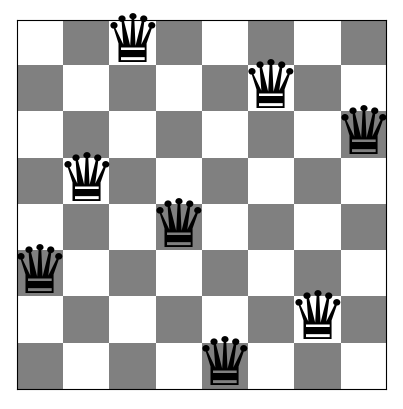

In [9]:
# Code và giải thích cho Task 4: Random Restart Hill Climbing
import time
import numpy as np
import random

def single_efficient_stochastic(board, max_trials=100):
    """Hàm Efficient Stochastic Hill Climbing chạy từ 1 trạng thái ban đầu"""
    current = np.array(board)
    n = len(current)
    current_score = conflicts(current)
    evals = 1
    steps = 0
    
    while True:
        steps += 1
        improved = False
        for _ in range(max_trials):
            col = random.randint(0, n - 1)
            row = random.randint(0, n - 1)
            while row == current[col]:
                row = random.randint(0, n - 1)
            
            neighbor = np.copy(current)
            neighbor[col] = row
            score = conflicts(neighbor)
            evals += 1
            
            if score < current_score:
                current = neighbor
                current_score = score
                improved = True
                break
        
        if not improved or current_score == 0:
            break
            
    return current, current_score, steps, evals

def random_restart_hill_climbing(n, max_restarts=100):
    """Thuật toán Hill Climbing với Random Restarts tối đa 100 lần"""
    best_board = None
    best_score = float('inf')
    total_steps = 0
    total_evals = 0
    restarts_used = 0
    
    start_time = time.time()
    
    for restart in range(max_restarts):
        restarts_used = restart + 1
        init_board = random_board(n)
        final_board, score, steps, evals = single_efficient_stochastic(init_board)
        
        total_steps += steps
        total_evals += evals
        
        if score < best_score:
            best_score = score
            best_board = final_board
            
        # Dừng sớm nếu tìm được lời giải không có xung đột (f = 0)
        if best_score == 0:
            break
            
    runtime = (time.time() - start_time) * 1000
    return best_board, best_score, total_steps, total_evals, restarts_used, runtime

# --- Chạy thử nghiệm Task 4 cho n = 8 ---
n = 8
best_board, best_f, steps, evals, restarts, runtime = random_restart_hill_climbing(n, max_restarts=100)
print(f"=== RANDOM RESTART HILL CLIMBING (n = {n}) ===")
print(f"Bàn cờ kết quả tốt nhất: {best_board}")
print(f"Số xung đột cuối cùng (f): {best_f}")
print(f"Số lần restart thực tế: {restarts} | Tổng bước lặp: {steps} | Số lần gọi conflicts(): {evals}")
print(f"Thời gian chạy: {runtime:.2f} ms")
show_board(best_board)

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

--- SIMULATED ANNEALING (n = 8) ---
Bàn cờ kết quả: [4 0 7 3 1 6 2 5]
Số xung đột cuối cùng (f): 0
Số lần gọi conflicts(): 497 | Thời gian: 3.87 ms
Board with 0 conflicts.


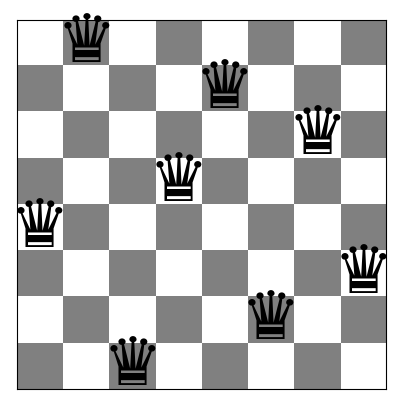

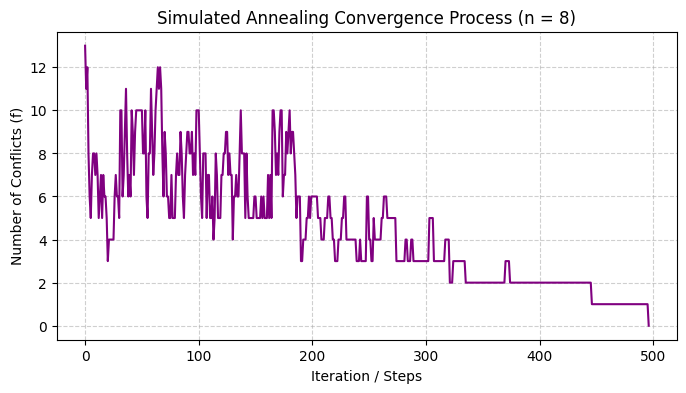

In [10]:
# Code và giải thích cho Task 5: Simulated Annealing
import time
import numpy as np
import matplotlib.pyplot as plt
import random

def simulated_annealing_n_queens(n, initial_temp=100.0, cooling_rate=0.99, max_iterations=5000):
    """Thuật toán Simulated Annealing cho bài toán n-Queens kèm theo lịch giảm nhiệt độ hàm mũ"""
    current = random_board(n)
    current_score = conflicts(current)
    
    best_board = np.copy(current)
    best_score = current_score
    
    temp = initial_temp
    eval_count = 1
    history_scores = [current_score]
    
    start_time = time.time()
    
    for t in range(1, max_iterations + 1):
        if current_score == 0:
            break
            
        # Sinh một láng giềng ngẫu nhiên
        col = random.randint(0, n - 1)
        row = random.randint(0, n - 1)
        while row == current[col]:
            row = random.randint(0, n - 1)
            
        neighbor = np.copy(current)
        neighbor[col] = row
        neighbor_score = conflicts(neighbor)
        eval_count += 1
        
        # Tính delta năng lượng (chênh lệch số xung đột)
        delta = neighbor_score - current_score
        
        # Chấp nhận bước nhảy nếu tốt hơn hoặc chấp nhận bước xấu theo xác suất Boltzmann
        if delta < 0 or random.random() < np.exp(-delta / temp):
            current = neighbor
            current_score = neighbor_score
            
            if current_score < best_score:
                best_board = np.copy(current)
                best_score = current_score
                
        history_scores.append(current_score)
        
        # Giảm nhiệt độ theo thời gian (Lịch giảm nhiệt độ hàm mũ)
        temp *= cooling_rate
        if temp < 1e-5:
            break
            
    runtime = (time.time() - start_time) * 1000
    return best_board, best_score, eval_count, runtime, history_scores

# --- Chạy thử nghiệm Task 5 cho n = 8 ---
n = 8
best_board, best_f, evals, runtime, history = simulated_annealing_n_queens(n, initial_temp=50.0, cooling_rate=0.985, max_iterations=10000)
print(f"--- SIMULATED ANNEALING (n = {n}) ---")
print(f"Bàn cờ kết quả: {best_board}")
print(f"Số xung đột cuối cùng (f): {best_f}")
print(f"Số lần gọi conflicts(): {evals} | Thời gian: {runtime:.2f} ms")
show_board(best_board)

# --- Vẽ đồ thị hội tụ ---
plt.figure(figsize=(8, 4))
plt.plot(history, color='purple', linewidth=1.5)
plt.title(f"Simulated Annealing Convergence Process (n = {n})")
plt.xlabel("Iteration / Steps")
plt.ylabel("Number of Conflicts (f)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [11]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [12]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [13]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [14]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Implement a Genetic Algorithm for the n-Queens problem

In [15]:
# Code and description go here


Board size: 4x4
Board: [2 3 3 0]
Board with 2 conflicts.


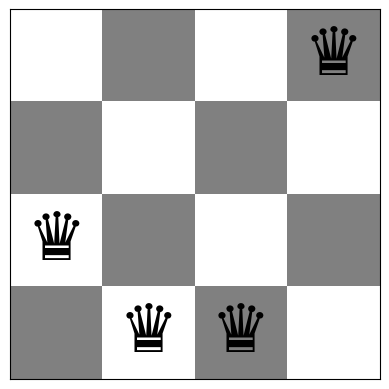

h(board) = 2

Board size: 8x8
Board: [2 3 6 4 1 7 5 4]
Board with 6 conflicts.


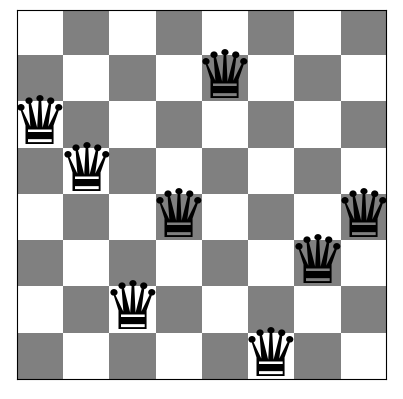

h(board) = 6


In [16]:
for n in [4, 8]:
    board = random_board(n)

    print(f"\nBoard size: {n}x{n}")
    print(f"Board: {board}")
    show_board(board)
    print(f"h(board) = {conflicts(board)}")

Board with 0 conflicts.


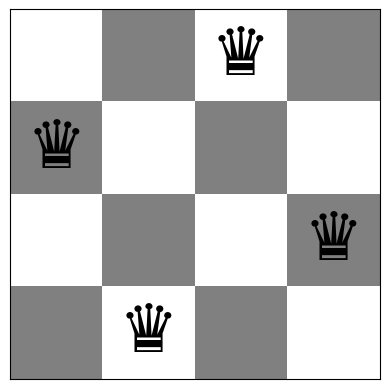

Board: [1, 3, 0, 2]
h(board) = 0
No attacking pairs: True


In [17]:
# Kiểm tra bàn cờ mẫu đã biết là không có xung đột
board = [1, 3, 0, 2]

show_board(board)

h = conflicts(board)
print(f"Board: {board}")
print(f"h(board) = {h}")
print(f"No attacking pairs: {h == 0}")

assert h == 0, "The sample board should have no conflicts."